In [1]:
!pip install -q deepagents langchain langchain-openai langgraph

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.4/353.4 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.2/65.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.0/573.0 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 862.0/862.0 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.0/268.0 kB 19.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the 

In [2]:
from pathlib import Path
from types import SimpleNamespace

from langchain_openai import ChatOpenAI

# ---- Config: change these ----------------------------------------------------------
api_key=""
MODEL = "gpt-5"

TRIGGER = 6000

OUT_DIR = Path("demo_output")
# -----------------------------------------------------------------------------------

# One model object, reused by every agent below.
# One model object, reused by every agent below.
llm = ChatOpenAI(model=MODEL, api_key=api_key)

OUT_DIR.mkdir(parents=True, exist_ok=True)
args = SimpleNamespace(model=llm, model_name=MODEL, trigger=TRIGGER, out_dir=OUT_DIR)
print("model:", MODEL, "| outputs ->", args.out_dir.resolve())

model: gpt-5 | outputs -> /content/demo_output


In [3]:
import json
import random

from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.tools import tool


class ContextMeter(BaseCallbackHandler):
    """Collects per-model-call token usage plus markers for huge tool results."""

    def __init__(self, label: str):
        self.label = label
        self.rows: list[dict] = []
        self.events: list[dict] = []
        self._pending: dict = {}

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, **kwargs):
        n_messages = len(messages[0]) if messages else 0
        self._pending[run_id] = (n_messages, (metadata or {}).get("lc_source"))

    def on_llm_end(self, response, *, run_id, **kwargs):
        n_messages, source = self._pending.pop(run_id, (0, None))
        usage = {}
        try:
            usage = response.generations[0][0].message.usage_metadata or {}
        except Exception:
            pass
        row = {
            "call": len(self.rows) + 1,
            "source": source or "agent",
            "messages": n_messages,
            "input": usage.get("input_tokens", 0),
            "output": usage.get("output_tokens", 0),
        }
        self.rows.append(row)
        tag = " <-- SUMMARIZATION" if row["source"] == "summarization" else ""
        print(
            f"  [{self.label:5}] call {row['call']:>2} | msgs {row['messages']:>3} | "
            f"input {row['input']:>7,} | output {row['output']:>6,}{tag}"
        )

    def on_tool_end(self, output, **kwargs):
        size = len(str(getattr(output, "content", output)))
        if size > 40_000:
            self.events.append({"after_call": len(self.rows), "kind": "huge_tool_result", "chars": size})
            print(f"  [{self.label:5}] >>> tool returned {size:,} characters")

In [4]:
_WORDS = (
    "latency throughput shard replica index vector token cache queue stream batch node "
    "cluster policy router buffer metric trace span window budget limit retry timeout "
    "schema column filter score rank embed chunk merge split commit flush"
).split()


def _filler(seed: str, chars: int, needle: str | None = None) -> str:
    rnd = random.Random(seed)
    out, total = [], 0
    while total < chars:
        sent = " ".join(rnd.choice(_WORDS) for _ in range(rnd.randint(8, 16))).capitalize() + "."
        out.append(sent)
        total += len(sent) + 1
    if needle:
        out.insert(len(out) // 2, needle)
    return "\n".join(out)  # one sentence per line, so line-based previews and grep behave realistically


@tool
def fetch_page(page_id: str) -> str:
    """Fetch the full text of a long internal report by its id (e.g. 'alpha-report')."""
    needle = None
    if page_id == "alpha-report":
        needle = "NOTE: The Zephyr-9 cache TTL is 47 seconds."
    elif page_id == "beta-report":
        needle = "NOTE: The Orion-3 retry limit is 5."
    return f"# {page_id}\n\n" + _filler(page_id, 120_000, needle)  # ~30k tokens


@tool
def lookup_fact(fact_id: int) -> str:
    """Look up a reference fact by integer id. Returns a few paragraphs of background text."""
    return f"FACT {fact_id}\n" + _filler(f"fact-{fact_id}", 3_000)


_page = fetch_page.invoke({"page_id": "alpha-report"})
print(f"fetch_page -> {len(_page):,} chars, {_page.count(chr(10)):,} lines, ~{len(_page) // 4:,} tokens (chars/4 estimate)")

fetch_page -> 120,062 chars, 1,482 lines, ~30,015 tokens (chars/4 estimate)


In [5]:
NO_SUBAGENTS = "Do not delegate to subagents; do the work yourself with the tools you have."


def build_naive(model, tools: list, system_prompt: str):
    # `model` is the ChatOpenAI instance from the config cell (llm).
    from langchain.agents import create_agent

    return create_agent(model, tools=tools, system_prompt=system_prompt)


def build_deep(model, tools: list, system_prompt: str, middleware: list | None = None):
    from deepagents import create_deep_agent

    return create_deep_agent(
        tools=tools,
        system_prompt=system_prompt,
        model=model,            # e.g. ChatOpenAI(model=MODEL, api_key=api_key)
        middleware=middleware or [],
    )


def run(agent, prompt: str, meter: ContextMeter) -> dict:
    return agent.invoke(
        {"messages": [{"role": "user", "content": prompt}]},
        config={"callbacks": [meter], "recursion_limit": 100},
    )


def text_of(message) -> str:
    content = getattr(message, "content", message)
    if isinstance(content, list):
        return "".join(b.get("text", "") for b in content if isinstance(b, dict))
    return str(content)


def file_chars(f) -> str:
    """Size of a virtual file, tolerant of the file-data shape changing between versions."""
    if isinstance(f, dict):
        c = f.get("content")
        if isinstance(c, list):
            return f"{len(chr(10).join(c)):,} chars"
        if isinstance(c, str):
            return f"{len(c):,} chars"
    return "? chars"

In [6]:
import matplotlib.pyplot as plt


def chart(title: str, meters: list, path: Path):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = {"naive": "#d9534f", "deep": "#2b7de9"}
    for m in meters:
        main = [r for r in m.rows if r["source"] != "summarization"]
        ax.plot([r["call"] for r in main], [r["input"] for r in main],
                marker="o", label=m.label, color=colors.get(m.label))
        for r in m.rows:
            if r["source"] == "summarization":
                ax.axvline(r["call"], color="#e8a317", linestyle="--", alpha=0.8)
                ax.text(r["call"], ax.get_ylim()[1] * 0.95, " summarization", color="#e8a317", va="top")
        for ev in m.events:
            ax.axvline(ev["after_call"] + 0.5, color="gray", linestyle=":", alpha=0.7)
            ax.text(ev["after_call"] + 0.5, ax.get_ylim()[1] * 0.85, " huge tool result", color="gray", va="top")
    ax.set_title(title)
    ax.set_xlabel("model call #")
    ax.set_ylabel("input tokens sent to the model")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    print(f"chart saved: {path}")


def dump(meters: list, path: Path):
    path.write_text(json.dumps({m.label: {"rows": m.rows, "events": m.events} for m in meters}, indent=2))

=== ACT 1: large tool-result eviction ===

-- naive agent (huge results go straight into the message history) --
  [naive] call  1 | msgs   2 | input     207 | output    185
  [naive] >>> tool returned 120,081 characters
  [naive] >>> tool returned 120,062 characters
  [naive] call  2 | msgs   5 | input  42,090 | output    224
  answer: The Zephyr-9 cache TTL is 47 seconds, and the Orion-3 retry limit is 5.

-- deep agent (results over the threshold are offloaded to files) --
  [deep ] call  1 | msgs   2 | input   2,172 | output    185
  [deep ] >>> tool returned 120,081 characters
  [deep ] >>> tool returned 120,062 characters
  [deep ] call  2 | msgs   5 | input   2,896 | output    358
  [deep ] call  3 | msgs   7 | input   2,979 | output     32
  [deep ] call  4 | msgs   9 | input   3,062 | output    223
  answer: The Zephyr-9 cache TTL is 47 seconds and the Orion-3 retry limit is 5.

  files in agent state:
    /large_tool_results/call_BE5ueomLu3Ln7tniPjwcJfh4  (120,062 chars)
    

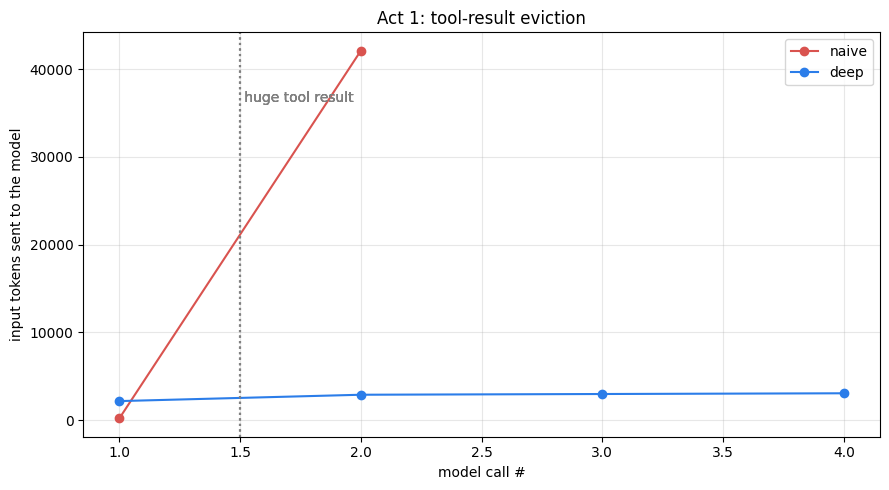

chart saved: demo_output/context_evict.png


In [7]:
def act_evict(args):
    print("=== ACT 1: large tool-result eviction ===")
    prompt = (
        "Fetch the pages 'alpha-report' and 'beta-report'. Find the Zephyr-9 cache TTL and the "
        "Orion-3 retry limit, and answer in one sentence. " + NO_SUBAGENTS
    )
    system = "You are a careful research assistant. Use fetch_page to read reports."
    naive_m, deep_m = ContextMeter("naive"), ContextMeter("deep")

    print("\n-- naive agent (huge results go straight into the message history) --")
    r = run(build_naive(args.model, [fetch_page], system), prompt, naive_m)
    print("  answer:", text_of(r["messages"][-1])[:300])

    print("\n-- deep agent (results over the threshold are offloaded to files) --")
    r = run(build_deep(args.model, [fetch_page], system), prompt, deep_m)
    print("  answer:", text_of(r["messages"][-1])[:300])

    print("\n  files in agent state:")
    for p, f in (r.get("files") or {}).items():
        print(f"    {p}  ({file_chars(f)})")

    print("\n  what the deep agent's context actually holds for the first fetch_page result:")
    for msg in r["messages"]:
        if getattr(msg, "type", "") == "tool" and getattr(msg, "name", "") == "fetch_page":
            body = text_of(msg)
            print(f"  ({len(body):,} chars in context, instead of ~120,000)\n")
            print("  " + body[:900].replace("\n", "\n  "))
            break

    chart("Act 1: tool-result eviction", [naive_m, deep_m], args.out_dir / "context_evict.png")
    dump([naive_m, deep_m], args.out_dir / "context_evict.json")
    return r


act1_result = act_evict(args)

=== ACT 2: auto-summarization ===

-- naive agent (history only grows) --
  [naive] call  1 | msgs   2 | input     219 | output    537
  [naive] call  2 | msgs   4 | input     737 | output     18
  [naive] call  3 | msgs   6 | input   1,266 | output     18
  [naive] call  4 | msgs   8 | input   1,786 | output     18
  [naive] call  5 | msgs  10 | input   2,321 | output    344
  [naive] call  6 | msgs  12 | input   2,847 | output    408
  [naive] call  7 | msgs  14 | input   3,377 | output     18
  [naive] call  8 | msgs  16 | input   3,913 | output     18
  [naive] call  9 | msgs  18 | input   4,429 | output     18
  [naive] call 10 | msgs  20 | input   4,966 | output     18
  [naive] call 11 | msgs  22 | input   5,500 | output     18
  [naive] call 12 | msgs  24 | input   6,020 | output     18
  [naive] call 13 | msgs  26 | input   6,541 | output     18
  [naive] call 14 | msgs  28 | input   7,067 | output     18
  [naive] call 15 | msgs  30 | input   7,591 | output    575
  answer: C

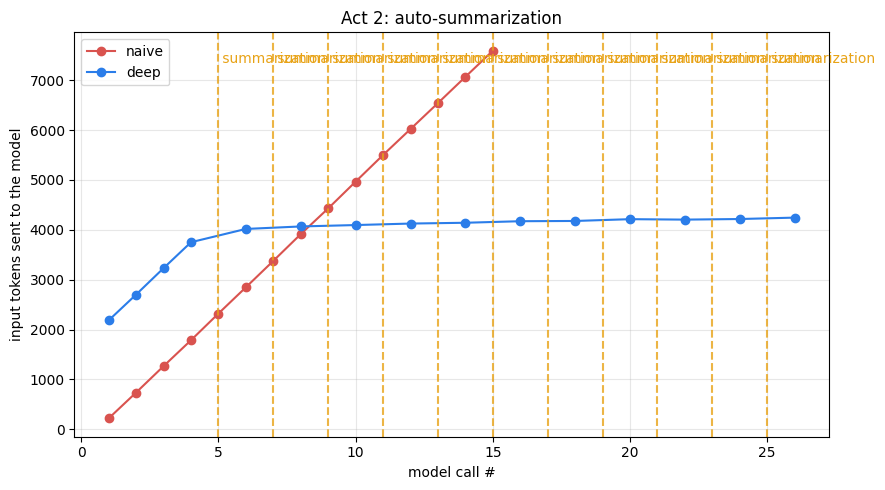

chart saved: demo_output/context_summarize.png


In [ ]:
def act_summarize(args):
    print("=== ACT 2: auto-summarization ===")
    from deepagents.backends import StateBackend
    from deepagents.middleware import SummarizationMiddleware

    prompt = (
        "Remember this: the client's deadline is Nov 12. Now call lookup_fact for ids 1 through "
        "14, ONE call at a time, in order. After the last one, tell me the client's deadline and "
        "list the fact ids you retrieved. " + NO_SUBAGENTS
    )
    system = "You are a methodical assistant. Follow the user's steps exactly."
    naive_m, deep_m = ContextMeter("naive"), ContextMeter("deep")

    print("\n-- naive agent (history only grows) --")
    r = run(build_naive(args.model, [lookup_fact], system), prompt, naive_m)
    print("  answer:", text_of(r["messages"][-1])[:300])

    print(f"\n-- deep agent (summarize once context exceeds {args.trigger:,} tokens; demo setting) --")
    custom = SummarizationMiddleware(
        model=args.model,
        backend=StateBackend(),
        trigger=("tokens", args.trigger),#6000 tokens
        keep=("messages", 6),
    )
    r = run(build_deep(args.model, [lookup_fact], system, middleware=[custom]), prompt, deep_m)
    print("  answer:", text_of(r["messages"][-1])[:300])
    print("\n  files in agent state (the full pre-summary history should be saved here):")
    for p, f in (r.get("files") or {}).items():
        print(f"    {p}  ({file_chars(f)})")
    print("  message count at end:", len(r["messages"]))

    chart("Act 2: auto-summarization", [naive_m, deep_m], args.out_dir / "context_summarize.png")
    dump([naive_m, deep_m], args.out_dir / "context_summarize.json")
    return r


act2_result = act_summarize(args)